# Pós-Graduação em IA Aplicada
### Unidade Curricular: Machine Learning
**Professor:** Giancarlo Marchesini, Me.

---

# Detecção de Anomalias

Nesta aula, exploramos um dos aspectos mais intrigantes e desafiadores da análise de dados: identificar observações que destoam do restante. As anomalias, também chamadas de *outliers*, podem conter informações valiosas (uma fraude, uma falha de equipamento, um comportamento raro e importante) ou podem ser apenas ruído — e saber diferenciar as duas coisas é o que torna essa tarefa interessante.

Começamos definindo o que são anomalias e por que importam em contextos tão diferentes quanto segurança cibernética, manutenção preditiva e detecção de fraude financeira. Em seguida, comparamos **sete métodos** de detecção — dois estatísticos (Z-Score, Interquartil) e cinco baseados em aprendizado de máquina (Isolation Forest, One-Class SVM, Local Outlier Factor, Elliptic Envelope e K-Means) — aplicando todos a um dataset público real de fraude em cartão de crédito, com métricas de verdade (Precision, Recall, F1, ROC-AUC, PR-AUC) e as armadilhas que mais aparecem na prática.

**Formato:** 1 aula de 3h.

> ▶️ **Como usar no Google Colab:** `Arquivo > Fazer upload de notebook`, envie este `.ipynb` e execute as células **em ordem** (`Ambiente de execução > Executar tudo` também funciona). O dataset é baixado automaticamente na primeira execução — é preciso estar conectado à internet.

## 1. Objetivos

Ao final desta aula, vocês devem ser capazes de:

1. Definir o que é uma anomalia e diferenciar os principais tipos (pontual x contextual, global x local, persistente x temporal).
2. Diferenciar *outlier detection* de *novelty detection*, e entender por que essa distinção muda a forma de usar cada método.
3. Explicar a intuição, as vantagens e as limitações de sete métodos de detecção de anomalias: Z-Score, Interquartil (IQR), Isolation Forest, One-Class SVM, Local Outlier Factor, Elliptic Envelope e K-Means.
4. Aplicar todos esses métodos, via `Pipeline` do scikit-learn, a um dataset real de fraude em cartão de crédito.
5. Avaliar os resultados com Precision, Recall, F1, ROC-AUC e PR-AUC, entendendo por que a PR-AUC costuma ser mais informativa sob forte desbalanceamento.
6. Reconhecer armadilhas comuns: a suposição embutida no parâmetro `contamination`/`nu`, o vazamento de dados no escalonamento, e o risco de assumir a forma errada para os dados "normais".

## 2. Introdução à Detecção de Anomalias

A detecção de anomalias, também conhecida como detecção de *outliers*, é uma área fundamental da ciência de dados que se concentra em identificar observações ou padrões que se desviam significativamente do comportamento esperado em um conjunto de dados. Anomalias podem ter origens muito diferentes — erros de medição, falhas de sistema, fraudes, comportamentos incomuns ou condições excepcionais — e detectá-las é essencial para garantir operações seguras, otimizar processos e identificar riscos ou oportunidades ocultos.

Essa tarefa aparece em praticamente todo setor: em segurança cibernética, identificar atividades suspeitas ajuda a detectar ataques e intrusões; na indústria, a manutenção preditiva usa detecção de anomalias para antecipar falhas de equipamento antes que elas causem parada não planejada; no setor financeiro, é a base da detecção de fraude em transações.

Detectar anomalias é desafiador por natureza: elas variam amplamente em forma e origem, nem sempre existe uma definição única e estável do que é "normal" (o padrão normal pode mudar ao longo do tempo), e, por serem raras quase por definição, é difícil reunir exemplos suficientes delas para treinar ou validar um modelo com confiança.

## 3. Tipos de Anomalias

**3.1 Anomalias pontuais (univariadas) x anomalias contextuais (multivariadas)**

- **Pontuais (univariadas):** ocorrem numa única variável — um valor extremamente alto ou baixo numa medida isolada já basta para caracterizá-las.
- **Contextuais (multivariadas):** cada variável, isolada, pode parecer perfeitamente normal; é a **combinação** entre elas que é incomum. São mais difíceis de detectar, porque exigem olhar para mais de uma dimensão ao mesmo tempo — veremos um exemplo concreto disso no Módulo 5.1.

**3.2 Anomalias globais x anomalias locais**

- **Globais:** destoam de todo o conjunto de dados — fáceis de notar olhando estatísticas gerais (média, desvio padrão).
- **Locais:** destoam só da sua vizinhança mais próxima, mesmo sem ser extremas em termos globais. Exigem métodos sensíveis a densidade local (como o LOF, Módulo 5.5) para serem capturadas.

**3.3 Anomalias persistentes x anomalias temporais**

- **Persistentes:** aparecem de forma consistente ao longo de todo o período observado.
- **Temporais:** surgem só em certos momentos ou condições — exigem olhar tendências e padrões ao longo do tempo, não só o dataset como uma "foto única".

## 4. *Outlier Detection* x *Novelty Detection*

Antes de entrar nos métodos, uma distinção que muda como cada um deles deve ser usado na prática:

- **Outlier detection:** o conjunto de dados usado para ajustar o modelo **já contém** as anomalias misturadas aos dados normais; o objetivo é encontrá-las dentro desse mesmo conjunto.
- **Novelty detection:** o conjunto usado para ajustar é considerado **limpo** (só dados normais); o objetivo é decidir, para pontos **novos**, se eles se parecem com o que foi visto no treino.

> 📌 **Por que isso importa.** Em produção, raramente temos rótulo disponível no momento do treino — o parâmetro `contamination` (ou `nu`, no One-Class SVM) é a nossa **suposição** de qual fração dos dados é anômala, não um fato calculado a partir de rótulos reais. No exemplo prático desta aula, usamos o rótulo de fraude **apenas para avaliar** os métodos depois de treinados, nunca para ajustá-los — exatamente como aconteceria em produção.

## 5. Métodos de Detecção de Anomalias

Comparamos sete métodos, divididos em dois grupos: **estatísticos** (Z-Score, Interquartil), mais simples e rápidos, bons como primeira checagem; e **baseados em aprendizado de máquina** (Isolation Forest, One-Class SVM, Local Outlier Factor, Elliptic Envelope, K-Means), capazes de capturar padrões multivariados mais complexos.

### 5.1 Estatístico — Z-Score

**Princípio.** Converte cada valor em "quantos desvios-padrão ele está da média":

$$z_i = \frac{x_i - \mu}{\sigma}$$

onde $x_i$ é o valor observado, $\mu$ a média e $\sigma$ o desvio padrão da variável. Pontos com `|z|` acima de um limiar (comumente 2 ou 3) são marcados como anômalos.

**Passos:** (1) calcular média e desvio padrão da variável; (2) calcular o Z-Score de cada ponto; (3) definir um limiar; (4) marcar como anomalia tudo que ultrapassar o limiar.

**Vantagens:** simples, rápido, fácil de explicar; não exige conhecimento prévio sobre a forma da distribuição.

**Limitações:** assume implicitamente uma distribuição aproximadamente normal (funciona mal em distribuições muito assimétricas ou com caudas longas); é **univariado** — avalia cada variável isoladamente, então não enxerga anomalias que só aparecem na combinação entre variáveis (Módulo 5.1 mais adiante tem um exemplo concreto disso).

**Quando usar:** primeira checagem rápida, variável por variável, antes de qualquer método mais sofisticado.

### 5.2 Estatístico — Interquartil (IQR)

**Princípio.** Em vez de média e desvio padrão (sensíveis a outliers), usa os quartis da distribuição, que são mais robustos. O primeiro quartil ($Q_1$) deixa 25% dos dados abaixo dele; o terceiro ($Q_3$) deixa 75%. A amplitude interquartil é $IQR = Q_3 - Q_1$, e os limites de corte são:

$$\text{Limite inferior} = Q_1 - 1.5 \times IQR \qquad \text{Limite superior} = Q_3 + 1.5 \times IQR$$

Qualquer valor fora desse intervalo é tratado como anomalia.

**Passos:** (1) calcular $Q_1$ e $Q_3$; (2) calcular o IQR; (3) calcular os limites; (4) marcar como anomalia tudo que estiver fora deles.

**Vantagens:** não assume distribuição normal, funciona bem mesmo com caudas longas; mais robusto a outliers extremos do que o Z-Score (porque quartis não são "puxados" por valores extremos como a média é).

**Limitações:** ainda é univariado (mesma limitação do Z-Score); o fator 1.5 é uma convenção, não uma lei — pode precisar de ajuste conforme o domínio.

**Quando usar:** alternativa ao Z-Score quando a variável tem distribuição visivelmente assimétrica ou com outliers extremos que distorceriam a média.

### 5.3 Isolation Forest

**Princípio.** Em vez de modelar o que é "normal", mede **quão fácil é isolar** cada ponto usando árvores de decisão aleatórias. Pontos anômalos, por estarem em regiões de baixa densidade, costumam ficar isolados com **poucos cortes aleatórios**; pontos normais, cercados de vizinhos parecidos, exigem muitos cortes até ficarem sozinhos.

**Como treina (`fit`).** Constrói várias árvores, cada uma particionando os dados com cortes aleatórios (variável e limiar sorteados a cada nó) até isolar cada ponto em sua própria folha. O comprimento médio do caminho até isolar um ponto, em todas as árvores, vira o **score de anomalia**: caminho curto → mais anômalo.

**Como infere (`predict`).** Retorna `1` (normal) ou `-1` (anomalia) usando `contamination` como limiar; `decision_function` dá o score contínuo.

**Vantagens:** rápido, lida bem com muitas variáveis, não exige suposição sobre a distribuição dos dados normais.

**Limitações:** ainda depende de uma boa estimativa de `contamination`; pode ter dificuldade com datasets muito pequenos.

**Quando usar:** primeira escolha para a maioria dos problemas de anomalia multivariada.

### 5.4 One-Class SVM

**Princípio.** Adapta a lógica do SVM de classificação (uma fronteira de decisão com margem máxima) para um problema sem duas classes: aprende uma **fronteira fechada** ao redor da região onde se concentram os dados normais (com o truque do kernel, permitindo fronteiras não lineares). Tudo que cai fora dela é tratado como anomalia.

**Como treina (`fit`).** Ajusta a fronteira de forma que uma fração `nu` dos pontos de treino fique **fora** dela — `nu` desempenha o mesmo papel do `contamination` dos outros métodos.

**Como infere.** `predict` retorna `1`/`-1`; `decision_function` dá a distância (assinada) até a fronteira.

**Vantagens:** captura fronteiras não lineares complexas; funciona bem quando a maioria dos dados é normal e não rotulada.

**Limitações:** sensível à escolha de kernel/hiperparâmetros; escala mal com datasets muito grandes (complexidade entre quadrática e cúbica em `n`); **exige padronização**.

**Quando usar:** dados normais concentrados numa região com fronteira complexa, em datasets de porte pequeno a médio.

### 5.5 Local Outlier Factor (LOF)

**Princípio.** Compara a densidade ao redor de um ponto com a densidade ao redor dos seus vizinhos mais próximos. Um ponto é anômalo quando sua vizinhança é muito **menos densa** que a vizinhança dos seus próprios vizinhos — por isso é especialmente bom em capturar **anomalias locais** (Módulo 3.2), que um método mais "global" como o Isolation Forest pode não notar.

**Como treina/infere.** ⚠️ **Aviso técnico.** O `LocalOutlierFactor` tem dois modos, controlados pelo parâmetro `novelty`:
- `novelty=False` (padrão): modo *transdutivo* — só tem `fit_predict`, sobre o próprio conjunto de treino. Chamar `.predict()` depois de `.fit()` nesse modo **gera erro**.
- `novelty=True`: habilita `.predict()`/`.decision_function()` para dado novo, mas pressupõe que o treino é majoritariamente normal (o cenário de *novelty detection* do Módulo 4).

**Vantagens:** captura anomalias locais que métodos globais perdem.

**Limitações:** sensível à escolha de `n_neighbors`; mais lento que o Isolation Forest em datasets grandes; fácil de usar o modo errado (`novelty`) sem perceber.

**Quando usar:** quando a "normalidade" tem densidades diferentes em regiões diferentes dos dados.

### 5.6 Elliptic Envelope

**Princípio.** O mais "estatístico" dos métodos baseados em ML: assume que os dados normais seguem, aproximadamente, uma **distribuição Gaussiana multivariada**, e ajusta uma elipse ao redor deles usando uma estimativa **robusta** de média e covariância (*Minimum Covariance Determinant*). A distância de cada ponto ao centro dessa elipse, ponderada pela covariância — a **distância de Mahalanobis** — vira o score de anomalia.

**Como treina/infere.** Mesmo padrão `fit`/`predict`/`decision_function` dos métodos anteriores, com `contamination` definindo o quantil de corte.

**Vantagens:** rápido; funciona bem quando a suposição Gaussiana é razoável.

**Limitações:** **falha de forma severa** quando os dados normais não são unimodais/elípticos (veremos um exemplo concreto disso no Módulo 7.4) — é o método mais sensível a essa suposição entre os sete.

**Quando usar:** quando há razão para acreditar que os dados normais realmente têm forma aproximadamente elíptica.

### 5.7 K-Means (baseado em clustering)

**Princípio.** Reaproveita o algoritmo de clustering (visto na aula de Aprendizado Não Supervisionado) para detecção de anomalias: ajusta `k` clusters sobre os dados (presumivelmente normais), e trata a **distância de cada ponto ao centróide mais próximo** como score de anomalia — pontos muito distantes de qualquer centróide não se encaixam bem em nenhum grupo "normal".

**Como treina/infere.** `fit` nos dados de treino; para cada ponto, `transform` retorna a distância a cada um dos `k` centróides — tomamos o mínimo (distância ao centróide mais próximo) e comparamos a um limiar (ex.: um percentil alto das distâncias de treino).

**Vantagens:** reaproveita um algoritmo já conhecido; funciona bem quando anomalias formam grupos isolados, longe de qualquer cluster normal.

**Limitações:** sensível à escolha de `k`; não funciona bem se as anomalias não formarem grupos distintos ou estiverem espalhadas entre os clusters normais; herda os pressupostos do K-Means (clusters aproximadamente esféricos).

**Quando usar:** quando se espera que os dados normais formem grupos bem definidos, e anomalias sejam pontos que não se encaixam bem em nenhum deles.

## 6. Exemplo Prático: Detecção de Fraude em Cartão de Crédito

Vamos aplicar os sete métodos a um dataset público real: transações de cartão de crédito de portadores europeus, em setembro de 2013, com fraudes confirmadas e rotuladas.

| Característica | Valor |
|---|---|
| Amostras no dataset completo | 284.807 transações |
| Classes | 2 — normal (0) e fraude (1); apenas **0,172%** das transações são fraude |
| Variáveis | 30: `Time`, `Amount` (valor da transação) e `V1`...`V28`, componentes resultantes de uma transformação PCA aplicada pelos autores originais para **anonimizar** os dados reais dos cartões |
| Valores faltantes | Nenhum |
| Fonte | Dal Pozzolo, A., Caelen, O., Johnson, R. A., & Bontempi, G. (2015). *Credit Card Fraud Detection*. Kaggle / OpenML (`data_id=1597`) |

Por confidencialidade, os autores aplicaram PCA nos dados originais antes de publicá-los — ganhamos um dataset genuíno e rotulado, perdemos a interpretabilidade direta de cada variável (não sabemos o que `V7` ou `V12`, por exemplo, representam de fato).

In [ ]:
# Bibliotecas usadas nesta aula
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_blobs, fetch_openml
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split

from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.neighbors import LocalOutlierFactor
from sklearn.covariance import EllipticEnvelope
from sklearn.cluster import KMeans
from sklearn.metrics import (
    precision_score, recall_score, f1_score, roc_auc_score, roc_curve,
    precision_recall_curve, average_precision_score,
)

SEMENTE = 42
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100


def plotar_anomalias(x, y, flag, titulo):
    """Espalha os pontos e destaca em vermelho os marcados como anomalia."""
    plt.figure(figsize=(8, 4.5))
    plt.scatter(x[flag == 0], y[flag == 0], s=10, alpha=0.4, color="steelblue", label="Normal")
    plt.scatter(x[flag == 1], y[flag == 1], s=18, color="crimson", label="Anomalia")
    plt.xlabel("Índice da transação"); plt.ylabel("Amount (valor da transação)")
    plt.title(titulo)
    plt.legend()
    plt.tight_layout()
    plt.show()


print("Bibliotecas prontas.")

Bibliotecas prontas.


### 6.1 Carregando o dataset

In [ ]:
pacote_fraude = fetch_openml(data_id=1597, as_frame=True, target_column=None, parser="auto")
df_fraude_bruto = pacote_fraude.data

# A coluna-alvo e' a unica com exatamente 2 valores possiveis (0/1) -- identificamos assim
# em vez de hardcodar o nome exato (datasets de terceiros podem variar a capitalizacao).
coluna_classe = [c for c in df_fraude_bruto.columns if df_fraude_bruto[c].nunique() == 2][0]
df_fraude_completo = df_fraude_bruto.drop(columns=[coluna_classe]).copy()
df_fraude_completo["fraude"] = df_fraude_bruto[coluna_classe].astype(int)

print(f"Dataset completo: {df_fraude_completo.shape[0]:,} transações".replace(",", ".")
      + f" — {df_fraude_completo['fraude'].sum()} fraudes "
      f"({df_fraude_completo['fraude'].mean():.3%})")

Dataset completo: 284.807 transações — 492 fraudes (0.173%)


> ⚠️ **Aviso de desempenho — leiam antes de seguir.** O dataset completo tem quase 285 mil transações (o download acontece uma vez; o scikit-learn faz cache automático depois disso). Treinar sete métodos — em especial o One-Class SVM, que escala mal com `n` — nesse volume inteiro tornaria a demonstração ao vivo impraticável. Para a aula, mantemos **todas as 492 fraudes reais** e uma amostra aleatória de transações normais, chegando a um dataset menor, mas com uma taxa de fraude bem mais alta (~9%) do que a real (0,17%) — só para o notebook rodar em segundos.

In [ ]:
fraudes = df_fraude_completo[df_fraude_completo["fraude"] == 1]
normais_amostra = df_fraude_completo[df_fraude_completo["fraude"] == 0].sample(n=5008, random_state=SEMENTE)
df_transacoes = pd.concat([fraudes, normais_amostra]).sample(frac=1, random_state=SEMENTE).reset_index(drop=True)
nomes_colunas = [coluna for coluna in df_transacoes.columns if coluna != "fraude"]

print(df_transacoes["fraude"].value_counts(normalize=True).rename("proporção").round(3))

X_treino, X_teste, y_treino, y_teste = train_test_split(
    df_transacoes[nomes_colunas], df_transacoes["fraude"],
    test_size=0.3, stratify=df_transacoes["fraude"], random_state=SEMENTE,
)
indice_teste = np.arange(len(X_teste))
print(f"Treino: {len(X_treino)} transações ({y_treino.sum()} fraudes)")
print(f"Teste : {len(X_teste)} transações ({y_teste.sum()} fraudes)")

TAXA_CONTAMINACAO = y_treino.mean()
print(f"\nTaxa de contaminação usada como suposição: {TAXA_CONTAMINACAO:.3f}")

fraude
0    0.911
1    0.089
Name: proporção, dtype: float64
Treino: 3850 transações (344 fraudes)
Teste : 1650 transações (148 fraudes)

Taxa de contaminação usada como suposição: 0.089


> 📌 **Nota sobre o `stratify`.** Usamos estratificação para garantir que treino e teste tenham a mesma proporção de fraudes, e calculamos `TAXA_CONTAMINACAO` a partir de `y_treino` só porque, para fins didáticos, temos o rótulo disponível. Nenhum dos sete métodos abaixo usa `y_treino` para se ajustar — todos são treinados só com `X_treino`, exatamente como aconteceria em produção sem rótulo algum.

### 6.2 Aplicando o Z-Score

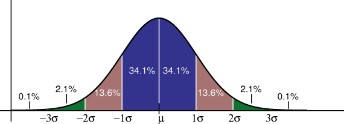

Variável usada como referência: Amount
Anomalias encontradas pelo Z-Score: 29 de 1650


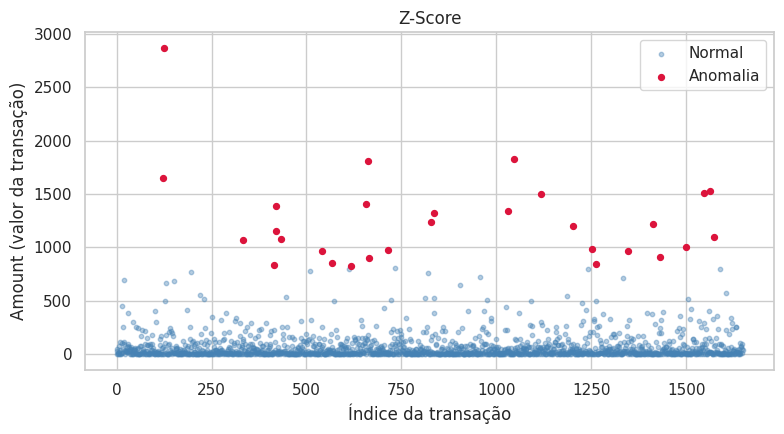

In [ ]:
# Usamos "Amount" (o valor da transação) como variável de referência: é a única variável
# com significado de negócio direto neste dataset -- V1...V28 vêm de um PCA anonimizador,
# e Time é só o instante da transação, sem relação direta com fraude.
coluna_referencia = "Amount"
print("Variável usada como referência:", coluna_referencia)

z_valor = (X_teste[coluna_referencia] - X_treino[coluna_referencia].mean()) / X_treino[coluna_referencia].std()
flag_zscore = (z_valor.abs() > 3).astype(int)

print(f"Anomalias encontradas pelo Z-Score: {flag_zscore.sum()} de {len(flag_zscore)}")
plotar_anomalias(indice_teste, X_teste["Amount"].values, flag_zscore.values, "Z-Score")

> 🚩 **Armadilha: um método univariado não enxerga anomalias multivariadas.** Um exemplo autocontido, independente do dataset principal, ilustra isso: valor da transação costuma acompanhar o histórico médio de gasto do cliente (correlação positiva). Uma transação pode estar **dentro da faixa normal em cada variável isoladamente**, e mesmo assim ser anômala pela combinação entre elas.

z do histórico: -0.01  |  z do valor: 1.93  -> nenhum passa de |z|=3
z do resíduo (valor vs. o que a correlação previa): 5.10


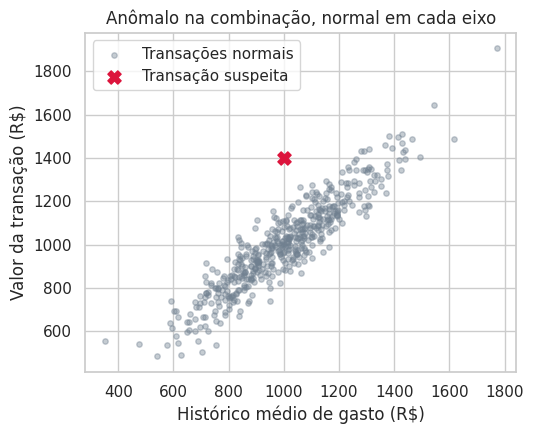

In [ ]:
rng_exemplo = np.random.RandomState(SEMENTE)
historico = rng_exemplo.normal(1000, 200, 500)
valor = historico + rng_exemplo.normal(0, 80, 500)  # segue o historico, com ruido pequeno

historico_suspeito, valor_suspeito = 1000, 1400  # normal em cada eixo, suspeito na combinacao

z_historico = (historico_suspeito - historico.mean()) / historico.std()
z_valor_exemplo = (valor_suspeito - valor.mean()) / valor.std()
print(f"z do histórico: {z_historico:.2f}  |  z do valor: {z_valor_exemplo:.2f}  -> nenhum passa de |z|=3")

coeficientes = np.polyfit(historico, valor, 1)
residuos_normais = valor - np.polyval(coeficientes, historico)
residuo_suspeito = valor_suspeito - np.polyval(coeficientes, historico_suspeito)
print(f"z do resíduo (valor vs. o que a correlação previa): {residuo_suspeito / residuos_normais.std():.2f}")

plt.figure(figsize=(5.5, 4.5))
plt.scatter(historico, valor, s=15, alpha=0.4, color="slategray", label="Transações normais")
plt.scatter([historico_suspeito], [valor_suspeito], color="crimson", s=90, marker="X", label="Transação suspeita")
plt.xlabel("Histórico médio de gasto (R$)"); plt.ylabel("Valor da transação (R$)")
plt.legend(); plt.title("Anômalo na combinação, normal em cada eixo")
plt.tight_layout()
plt.show()

> 📌 **Leitura.** Cada variável isolada não ultrapassa `|z|=3`, então o Z-score univariado **não sinalizaria nada**. Mas o resíduo em relação à correlação esperada é enorme. É exatamente esse tipo de padrão que os métodos multivariados a seguir conseguem capturar.

### 6.3 Aplicando o Interquartil (IQR)

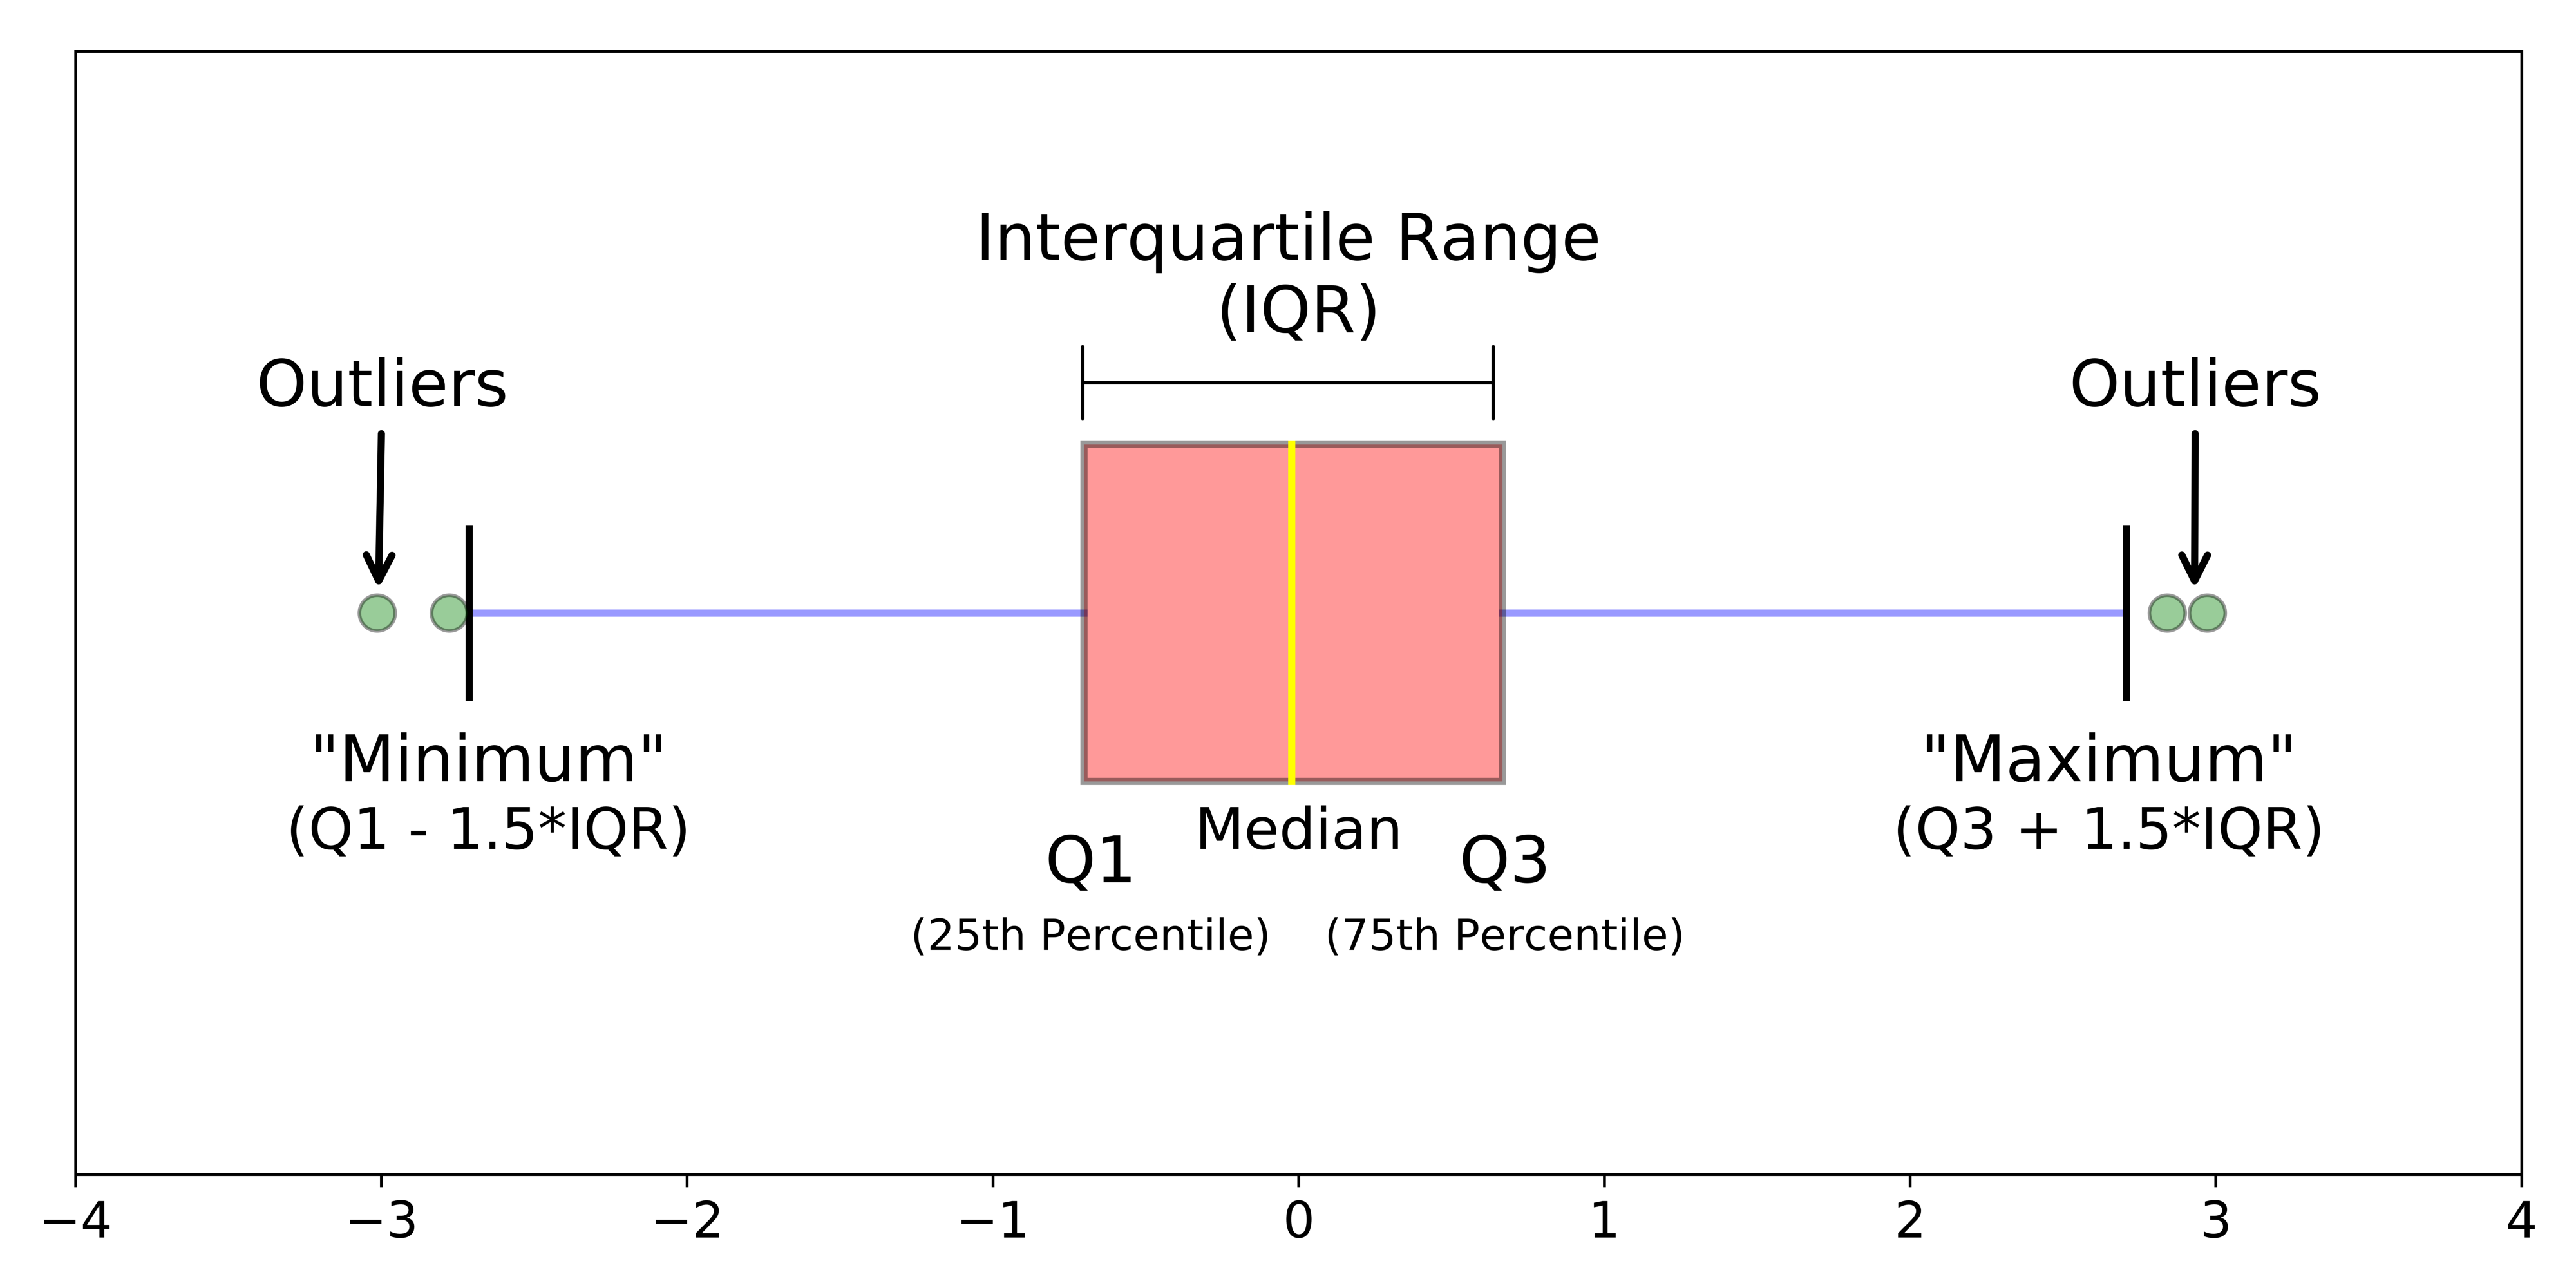

Limites: [-104.33, 185.86]
Anomalias encontradas pelo IQR: 190 de 1650


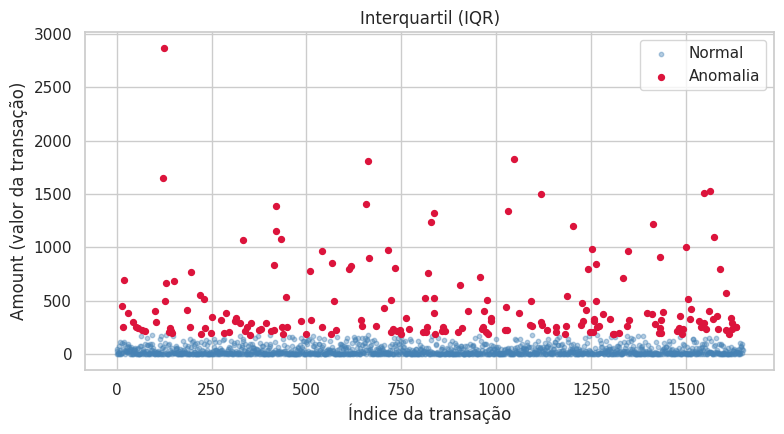

In [ ]:
Q1 = X_treino[coluna_referencia].quantile(0.25)
Q3 = X_treino[coluna_referencia].quantile(0.75)
IQR = Q3 - Q1
limite_inferior, limite_superior = Q1 - 3 * IQR, Q3 + 3 * IQR

flag_iqr = ((X_teste[coluna_referencia] < limite_inferior) | (X_teste[coluna_referencia] > limite_superior)).astype(int)

print(f"Limites: [{limite_inferior:.2f}, {limite_superior:.2f}]")
print(f"Anomalias encontradas pelo IQR: {flag_iqr.sum()} de {len(flag_iqr)}")
plotar_anomalias(indice_teste, X_teste["Amount"].values, flag_iqr.values, "Interquartil (IQR)")

Limites: [-358.25, 439.77]
Anomalias encontradas pelo IQR: 59 de 1650


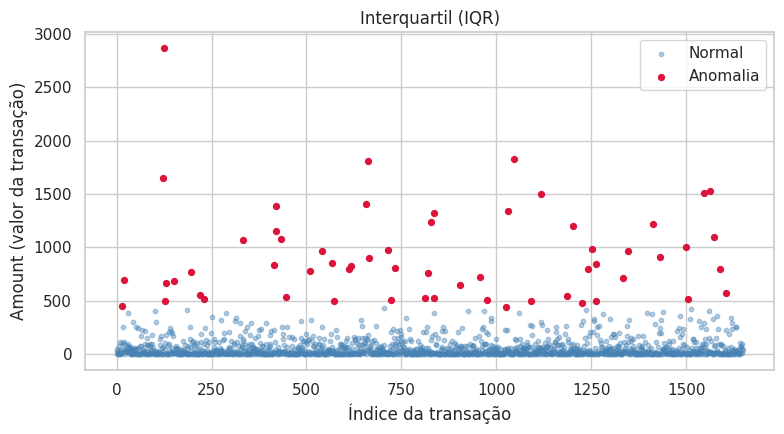

In [ ]:
Q1 = X_treino[coluna_referencia].quantile(0.25)
Q3 = X_treino[coluna_referencia].quantile(0.75)
IQR = Q3 - Q1
limite_inferior, limite_superior = Q1 - 5 * IQR, Q3 + 5 * IQR

flag_iqr = ((X_teste[coluna_referencia] < limite_inferior) | (X_teste[coluna_referencia] > limite_superior)).astype(int)

print(f"Limites: [{limite_inferior:.2f}, {limite_superior:.2f}]")
print(f"Anomalias encontradas pelo IQR: {flag_iqr.sum()} de {len(flag_iqr)}")
plotar_anomalias(indice_teste, X_teste["Amount"].values, flag_iqr.values, "Interquartil (IQR)")

> 📌 **Leitura.** Repare que o IQR tende a marcar **mais** pontos como anomalia do que o Z-Score sobre a mesma variável — ele não exige que a distribuição seja aproximadamente normal, então capta mais a cauda longa típica de valores monetários. Como `Amount` nunca é negativo e tem poucos valores muito altos, é comum o IQR sinalizar bem mais transações de valor alto que o Z-Score sinalizaria.

### 6.4 Aplicando o Isolation Forest

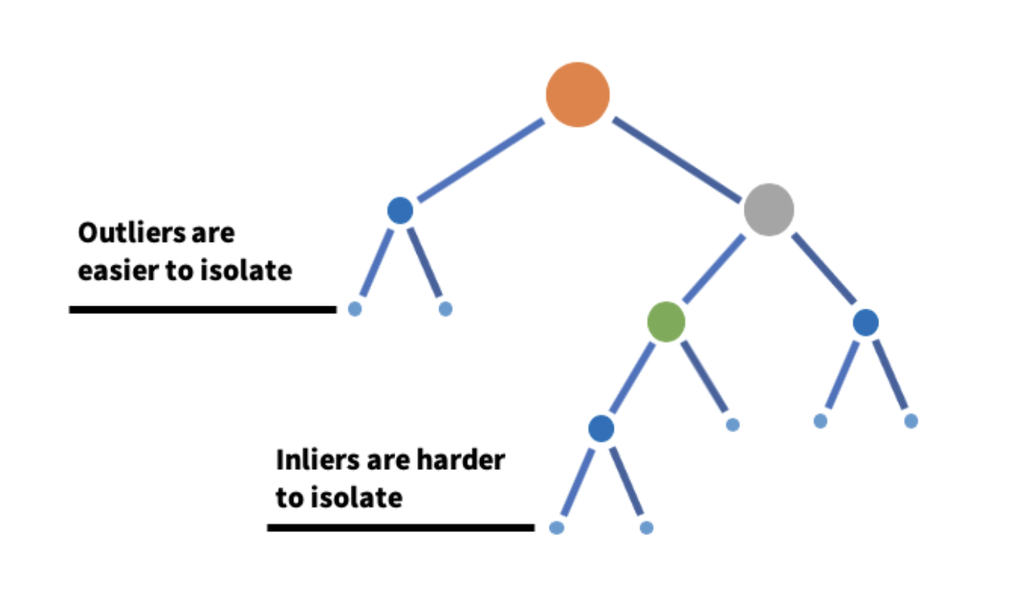

Anomalias encontradas pelo Isolation Forest: 136 de 1650


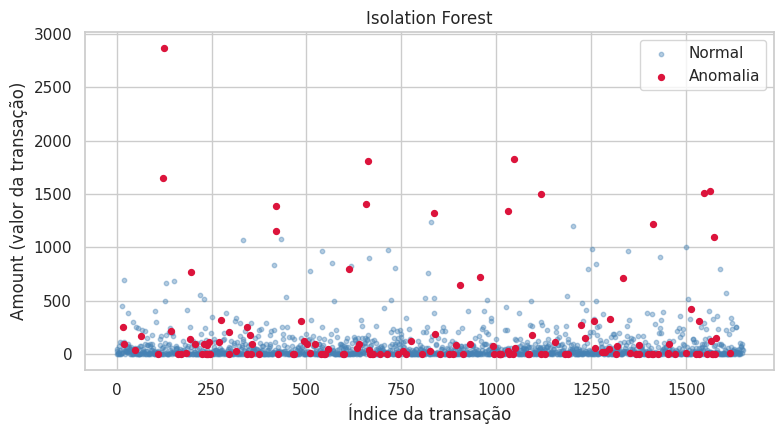

In [ ]:
pipeline_isolation_forest = Pipeline([
    ("escalonador", StandardScaler()),
    ("detector", IsolationForest(contamination=TAXA_CONTAMINACAO, random_state=SEMENTE)),
])
pipeline_isolation_forest.fit(X_treino)

flag_isolation_forest = (pipeline_isolation_forest.predict(X_teste) == -1).astype(int)
score_isolation_forest = -pipeline_isolation_forest.decision_function(X_teste)

print(f"Anomalias encontradas pelo Isolation Forest: {flag_isolation_forest.sum()} de {len(flag_isolation_forest)}")
plotar_anomalias(indice_teste, X_teste["Amount"].values, flag_isolation_forest, "Isolation Forest")

### 6.5 Aplicando o One-Class SVM

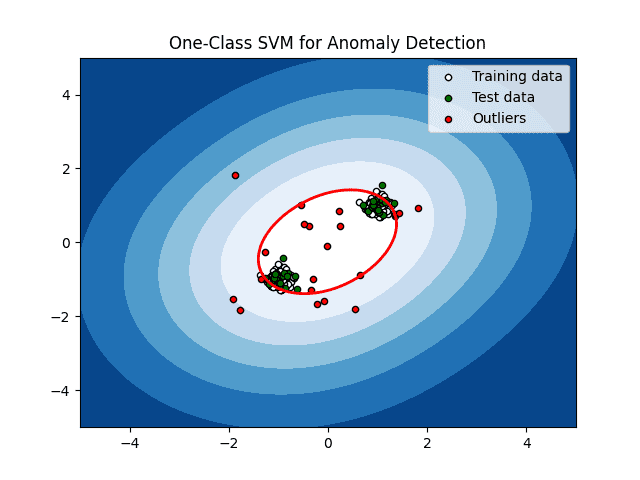

Anomalias encontradas pelo One-Class SVM: 123 de 1650


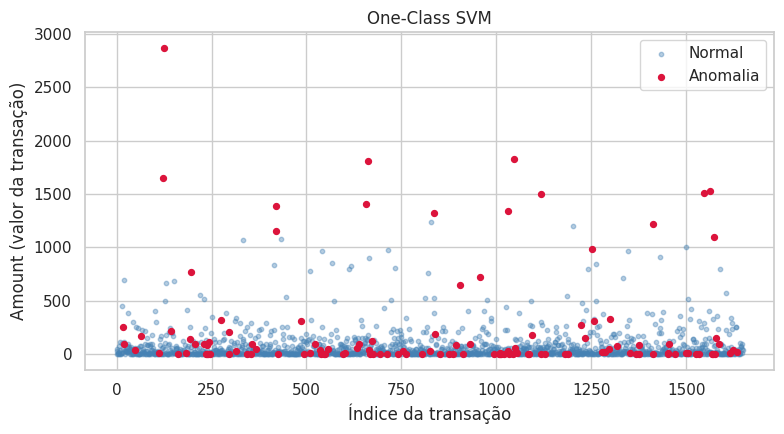

In [ ]:
pipeline_ocsvm = Pipeline([
    ("escalonador", StandardScaler()),
    ("detector", OneClassSVM(nu=TAXA_CONTAMINACAO, kernel="rbf", gamma="scale")),
])
pipeline_ocsvm.fit(X_treino)

flag_ocsvm = (pipeline_ocsvm.predict(X_teste) == -1).astype(int)
score_ocsvm = -pipeline_ocsvm.decision_function(X_teste)

print(f"Anomalias encontradas pelo One-Class SVM: {flag_ocsvm.sum()} de {len(flag_ocsvm)}")
plotar_anomalias(indice_teste, X_teste["Amount"].values, flag_ocsvm, "One-Class SVM")

### 6.6 Aplicando o Local Outlier Factor

Como queremos avaliar em `X_teste` (dado que o modelo não viu no treino), usamos `novelty=True` — veja o aviso técnico do Módulo 5.5.

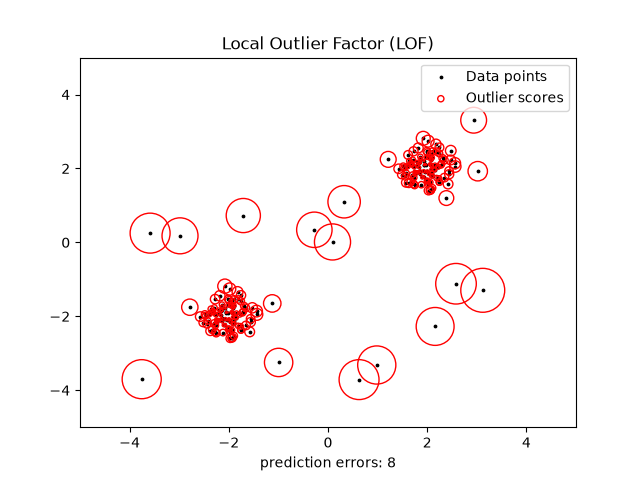

Anomalias encontradas pelo LOF: 108 de 1650


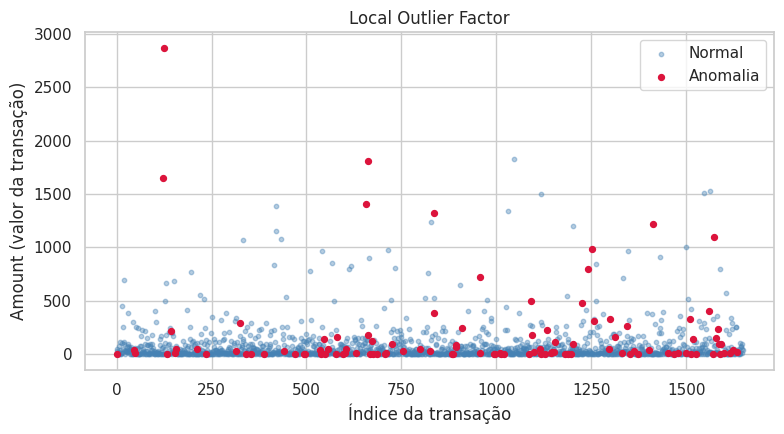

In [ ]:
pipeline_lof = Pipeline([
    ("escalonador", StandardScaler()),
    ("detector", LocalOutlierFactor(n_neighbors=20, contamination=TAXA_CONTAMINACAO, novelty=True)),
])
pipeline_lof.fit(X_treino)

flag_lof = (pipeline_lof.predict(X_teste) == -1).astype(int)
score_lof = -pipeline_lof.decision_function(X_teste)

print(f"Anomalias encontradas pelo LOF: {flag_lof.sum()} de {len(flag_lof)}")
plotar_anomalias(indice_teste, X_teste["Amount"].values, flag_lof, "Local Outlier Factor")

### 6.7 Aplicando o Elliptic Envelope

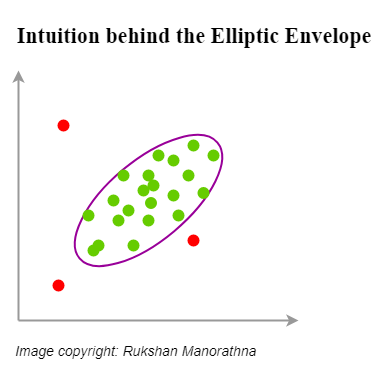

/usr/local/lib/python3.13/dist-packages/sklearn/covariance/_robust_covariance.py:185: RuntimeWarning: Determinant has increased; this should not happen: log(det) > log(previous_det) (-199.983889279539966 > -200.554618663829132). You may want to try with a higher value of support_fraction (current value: 0.504).
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/covariance/_robust_covariance.py:185: RuntimeWarning: Determinant has increased; this should not happen: log(det) > log(previous_det) (-202.927460090848399 > -203.606362071187306). You may want to try with a higher value of support_fraction (current value: 0.504).
  warnings.warn(


Anomalias encontradas pela Elliptic Envelope: 148 de 1650


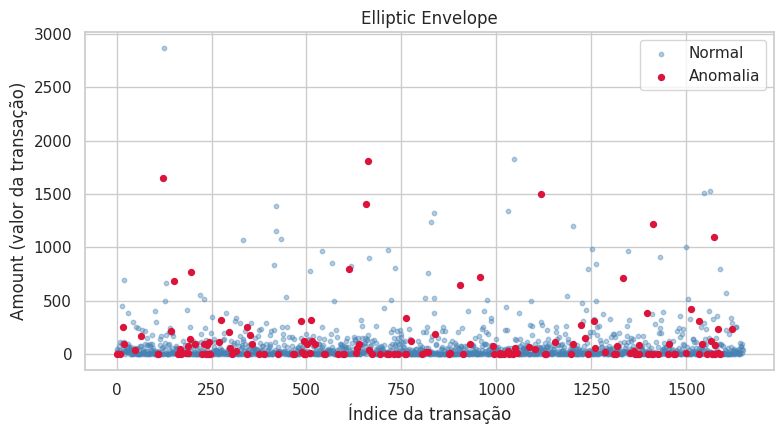

In [ ]:
pipeline_elliptic = Pipeline([
    ("escalonador", StandardScaler()),
    ("detector", EllipticEnvelope(contamination=TAXA_CONTAMINACAO, random_state=SEMENTE)),
])
pipeline_elliptic.fit(X_treino)

flag_elliptic = (pipeline_elliptic.predict(X_teste) == -1).astype(int)
score_elliptic = -pipeline_elliptic.decision_function(X_teste)

print(f"Anomalias encontradas pela Elliptic Envelope: {flag_elliptic.sum()} de {len(flag_elliptic)}")
plotar_anomalias(indice_teste, X_teste["Amount"].values, flag_elliptic, "Elliptic Envelope")

### 6.8 Aplicando o K-Means (baseado em clustering)

Ajustamos o K-Means só no treino (presumivelmente majoritário em dados normais) e usamos a distância ao centróide mais próximo como score: quanto mais longe de qualquer cluster "normal", mais suspeito.

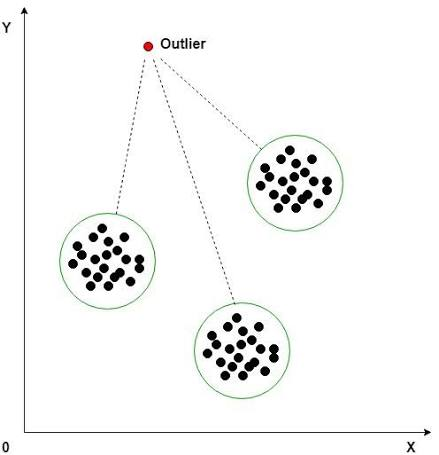

Anomalias encontradas pelo K-Means: 123 de 1650


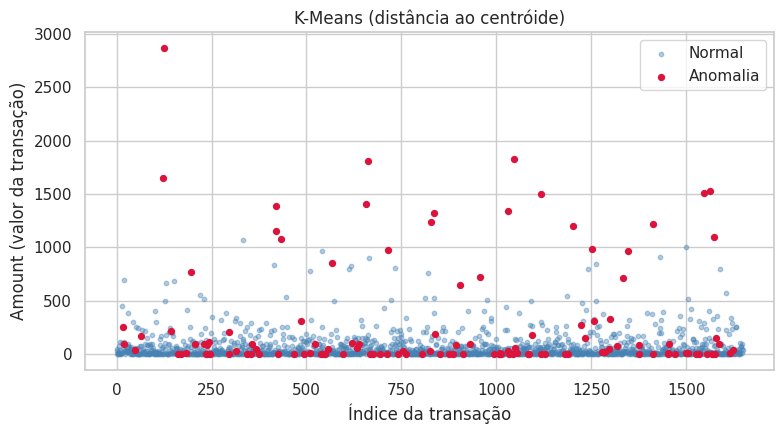

In [ ]:
pipeline_kmeans_base = Pipeline([
    ("escalonador", StandardScaler()),
    ("cluster", KMeans(n_clusters=4, random_state=SEMENTE, n_init=10)),
])
pipeline_kmeans_base.fit(X_treino)

distancias_treino = pipeline_kmeans_base.named_steps["cluster"].transform(
    pipeline_kmeans_base.named_steps["escalonador"].transform(X_treino)
).min(axis=1)
limiar_kmeans = np.percentile(distancias_treino, 100 * (1 - TAXA_CONTAMINACAO))

distancias_teste = pipeline_kmeans_base.named_steps["cluster"].transform(
    pipeline_kmeans_base.named_steps["escalonador"].transform(X_teste)
).min(axis=1)
flag_kmeans = (distancias_teste > limiar_kmeans).astype(int)
score_kmeans = distancias_teste

print(f"Anomalias encontradas pelo K-Means: {flag_kmeans.sum()} de {len(flag_kmeans)}")
plotar_anomalias(indice_teste, X_teste["Amount"].values, flag_kmeans, "K-Means (distância ao centróide)")

### 6.9 Comparando os sete métodos

Mesmo com a taxa de fraude "inflada" para ~9% nesta amostra, o problema continua desbalanceado o bastante para que **acurácia seja uma péssima bússola**: um modelo que sempre prevê "normal" já acerta ~91%. As métricas que importam:

- **Precision:** entre tudo que o modelo marcou como anomalia, quanto era mesmo anomalia.
- **Recall:** entre todas as fraudes reais, quantas o modelo encontrou.
- **F1:** média harmônica entre as duas.
- **ROC-AUC:** qualidade do *ranking* de scores — taxa de verdadeiros positivos x falsos positivos em todos os limiares possíveis.
- **PR-AUC (Average Precision):** Precision x Recall em todos os limiares. **Sob desbalanceamento, costuma ser mais informativa que a ROC-AUC**, que pode parecer artificialmente alta quando a classe negativa é enorme.

In [ ]:
# Scores continuos para Z-score e IQR, para completar ROC-AUC/PR-AUC dos sete métodos
score_zscore = z_valor.abs().values
score_iqr = np.maximum(limite_inferior - X_teste[coluna_referencia].values,
                        X_teste[coluna_referencia].values - limite_superior)

metodos_anomalia = {
    "Z-Score": (flag_zscore.values, score_zscore),
    "IQR": (flag_iqr.values, score_iqr),
    "Isolation Forest": (flag_isolation_forest, score_isolation_forest),
    "One-Class SVM": (flag_ocsvm, score_ocsvm),
    "Local Outlier Factor": (flag_lof, score_lof),
    "Elliptic Envelope": (flag_elliptic, score_elliptic),
    "K-Means": (flag_kmeans, score_kmeans),
}

resultados = []
for nome, (flag, score) in metodos_anomalia.items():
    resultados.append({
        "método": nome,
        "anomalias_encontradas": int(flag.sum()),
        "precision": precision_score(y_teste, flag, zero_division=0),
        "recall": recall_score(y_teste, flag, zero_division=0),
        "f1": f1_score(y_teste, flag, zero_division=0),
        "roc_auc": roc_auc_score(y_teste, score),
        "pr_auc": average_precision_score(y_teste, score),
    })

tabela_resultados = pd.DataFrame(resultados).set_index("método").round(3)
tabela_resultados

,anomalias_encontradas,precision,recall,f1,roc_auc,pr_auc
método,,,,,,
Z-Score,29,0.138,0.027,0.045,0.650,0.173
IQR,190,0.179,0.230,0.201,0.691,0.169
Isolation Forest,136,0.728,0.669,0.697,0.937,0.757
One-Class SVM,123,0.577,0.480,0.524,0.874,0.453
Local Outlier Factor,108,0.139,0.101,0.117,0.511,0.128
Elliptic Envelope,148,0.784,0.784,0.784,0.925,0.743
K-Means,123,0.569,0.473,0.517,0.876,0.458


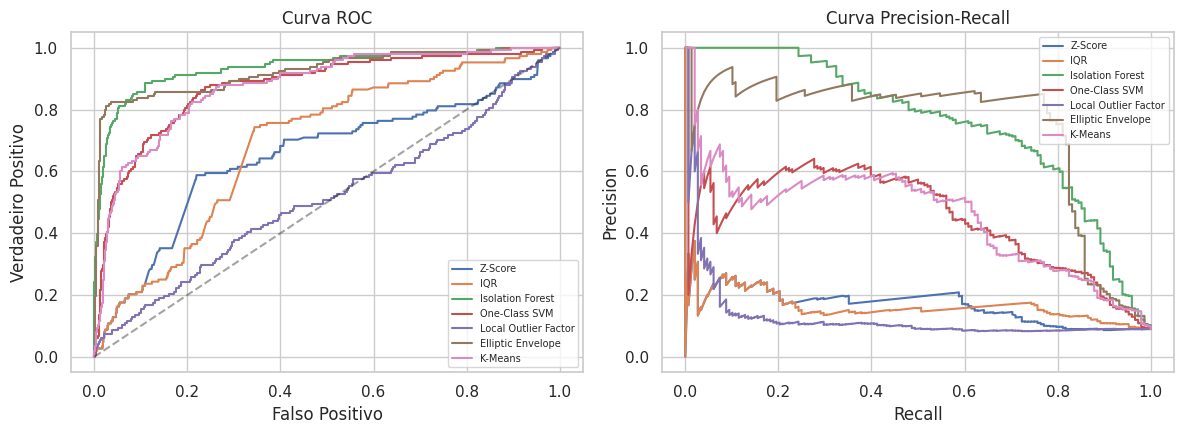

In [ ]:
figura, eixos = plt.subplots(1, 2, figsize=(12, 4.5))

for nome, (flag, score) in metodos_anomalia.items():
    fpr, tpr, _ = roc_curve(y_teste, score)
    eixos[0].plot(fpr, tpr, label=nome)
    precisao, recall_vals, _ = precision_recall_curve(y_teste, score)
    eixos[1].plot(recall_vals, precisao, label=nome)

eixos[0].plot([0, 1], [0, 1], "k--", alpha=0.4)
eixos[0].set_xlabel("Falso Positivo"); eixos[0].set_ylabel("Verdadeiro Positivo")
eixos[0].set_title("Curva ROC"); eixos[0].legend(fontsize=7)

eixos[1].set_xlabel("Recall"); eixos[1].set_ylabel("Precision")
eixos[1].set_title("Curva Precision-Recall"); eixos[1].legend(fontsize=7)

plt.tight_layout()
plt.show()

> 📌 **Leitura.** Olhem para qual método tem a curva ROC mais próxima do canto superior esquerdo e a curva PR mais próxima do canto superior direito — normalmente **não é o mesmo método** nas duas, e é aí que mora a decisão prática: um recall alto com muitos falsos positivos pode ser aceitável se o custo de revisar um alerta for baixo; uma precision alta com recall baixo pode ser preferível se cada alerta gerar uma ligação cara ao cliente. Métodos univariados (Z-Score, IQR) tendem a ficar atrás dos multivariados aqui — esperado, dado o que o Módulo 6.2 já mostrou sobre anomalias que só aparecem na combinação entre variáveis.

## 7. Armadilhas na Prática

### 7.1 `contamination`/`nu` é uma suposição, não um fato

Usamos `TAXA_CONTAMINACAO` porque é a taxa de fraude **na amostra que nós mesmos montamos** (Módulo 6.1) — não a taxa real do problema (0,17% no dataset completo). Em produção, normalmente não sabemos a taxa real de antemão.

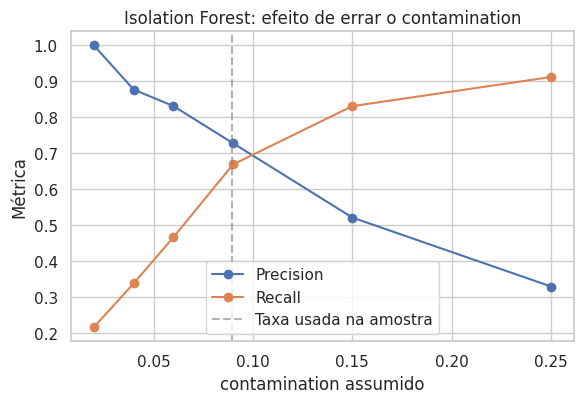

In [ ]:
valores_contaminacao = [0.02, 0.04, 0.06, 0.09, 0.15, 0.25]
precisoes, recalls = [], []
for contaminacao in valores_contaminacao:
    pipeline_teste = Pipeline([
        ("escalonador", StandardScaler()),
        ("detector", IsolationForest(contamination=contaminacao, random_state=SEMENTE)),
    ])
    pipeline_teste.fit(X_treino)
    flag_teste = (pipeline_teste.predict(X_teste) == -1).astype(int)
    precisoes.append(precision_score(y_teste, flag_teste, zero_division=0))
    recalls.append(recall_score(y_teste, flag_teste, zero_division=0))

plt.figure(figsize=(6, 4.2))
plt.plot(valores_contaminacao, precisoes, marker="o", label="Precision")
plt.plot(valores_contaminacao, recalls, marker="o", label="Recall")
plt.axvline(x=TAXA_CONTAMINACAO, color="gray", linestyle="--", alpha=0.6, label="Taxa usada na amostra")
plt.xlabel("contamination assumido"); plt.ylabel("Métrica")
plt.title("Isolation Forest: efeito de errar o contamination")
plt.legend()
plt.tight_layout()
plt.show()

> 🚩 **Leitura.** Superestimar `contamination` marca mais pontos como anômalos: o recall tende a subir, mas a precision cai (mais falsos positivos). Subestimar faz o oposto. Sem saber a taxa real, a escolha de `contamination` é, na prática, uma decisão de negócio sobre **qual erro custa mais caro**: deixar passar uma fraude (recall baixo) ou incomodar clientes legítimos com alertas falsos (precision baixa).

### 7.2 Vazamento de dados no escalonamento

O mesmo cuidado de qualquer pipeline de ML vale aqui: o `StandardScaler` só pode ver o conjunto de treino.

In [ ]:
# ERRADO: ajusta o escalonador com TODOS os dados (treino + teste) antes do split
escalonador_errado = StandardScaler().fit(pd.concat([X_treino, X_teste]))
X_teste_errado = escalonador_errado.transform(X_teste)
detector_errado = IsolationForest(contamination=TAXA_CONTAMINACAO, random_state=SEMENTE).fit(
    escalonador_errado.transform(X_treino)
)
score_errado = -detector_errado.decision_function(X_teste_errado)
print(f"ROC-AUC com vazamento : {roc_auc_score(y_teste, score_errado):.4f}")

# CERTO: ajusta o escalonador só com o treino
escalonador_certo = StandardScaler().fit(X_treino)
X_teste_certo = escalonador_certo.transform(X_teste)
detector_certo = IsolationForest(contamination=TAXA_CONTAMINACAO, random_state=SEMENTE).fit(
    escalonador_certo.transform(X_treino)
)
score_certo = -detector_certo.decision_function(X_teste_certo)
print(f"ROC-AUC sem vazamento : {roc_auc_score(y_teste, score_certo):.4f}")

ROC-AUC com vazamento : 0.9373
ROC-AUC sem vazamento : 0.9373


> 📌 **Leitura.** Com `StandardScaler` e um detector baseado em árvores (pouco sensível à escala), a diferença numérica aqui tende a ser pequena — mas o princípio vale sempre: **o conjunto de teste representa dados que o pipeline inteiro nunca deveria ter visto durante o ajuste, incluindo o escalonador**. Com detectores baseados em distância (LOF, One-Class SVM) ou datasets menores, esse vazamento pode inflar as métricas de forma bem mais visível.

### 7.3 *Outlier detection* x *novelty detection* — o erro mais comum na prática

Reforçando o aviso do Módulo 5.5: se você treinar um `LocalOutlierFactor` no modo padrão (`novelty=False`) e tentar usar `.predict()` em dado novo, o scikit-learn recusa a chamada.

In [ ]:
lof_padrao = LocalOutlierFactor(n_neighbors=20, contamination=TAXA_CONTAMINACAO)  # novelty=False, o padrao
lof_padrao.fit(X_treino)
try:
    lof_padrao.predict(X_teste)
except AttributeError as erro:
    print("Erro esperado:", erro)

Erro esperado: This 'LocalOutlierFactor' has no attribute 'predict'


### 7.4 Quando a "normalidade" não é Gaussiana

O Módulo 5.6 avisou: a Elliptic Envelope depende de os dados normais serem, de fato, aproximadamente Gaussianos. O exemplo abaixo, autocontido em 2D para facilitar a visualização, mostra o que acontece quando essa suposição é violada: dados normais **bimodais** (dois perfis legítimos bem distintos) com anomalias exatamente no "vale" entre os dois grupos.

Isolation Forest — ROC-AUC : 0.805
Elliptic Envelope — ROC-AUC: 0.057


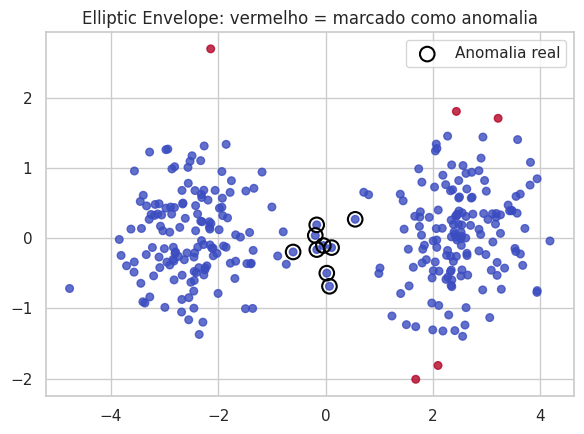

In [ ]:
X_normais_bimodal, _ = make_blobs(n_samples=970, centers=[[-2.5, 0], [2.5, 0]],
                                    cluster_std=0.7, random_state=SEMENTE)
rng_bimodal = np.random.RandomState(SEMENTE)
anomalias_no_vale = rng_bimodal.normal(loc=[0, 0], scale=0.35, size=(30, 2))

X_bimodal = np.vstack([X_normais_bimodal, anomalias_no_vale])
y_bimodal = np.array([0] * len(X_normais_bimodal) + [1] * len(anomalias_no_vale))
X_treino_bm, X_teste_bm, y_treino_bm, y_teste_bm = train_test_split(
    X_bimodal, y_bimodal, test_size=0.3, stratify=y_bimodal, random_state=SEMENTE
)

pipeline_if_bimodal = Pipeline([("escalonador", StandardScaler()),
                                  ("detector", IsolationForest(contamination=0.03, random_state=SEMENTE))])
pipeline_if_bimodal.fit(X_treino_bm)
score_if_bimodal = -pipeline_if_bimodal.decision_function(X_teste_bm)

pipeline_ee_bimodal = Pipeline([("escalonador", StandardScaler()),
                                  ("detector", EllipticEnvelope(contamination=0.03, random_state=SEMENTE))])
pipeline_ee_bimodal.fit(X_treino_bm)
flag_ee_bimodal = (pipeline_ee_bimodal.predict(X_teste_bm) == -1).astype(int)
score_ee_bimodal = -pipeline_ee_bimodal.decision_function(X_teste_bm)

print(f"Isolation Forest — ROC-AUC : {roc_auc_score(y_teste_bm, score_if_bimodal):.3f}")
print(f"Elliptic Envelope — ROC-AUC: {roc_auc_score(y_teste_bm, score_ee_bimodal):.3f}")

plt.figure(figsize=(6, 4.5))
plt.scatter(X_teste_bm[:, 0], X_teste_bm[:, 1], c=flag_ee_bimodal, cmap="coolwarm", s=30, alpha=0.8)
plt.scatter(X_teste_bm[y_teste_bm == 1, 0], X_teste_bm[y_teste_bm == 1, 1],
            facecolors="none", edgecolors="black", s=110, linewidths=1.5, label="Anomalia real")
plt.title("Elliptic Envelope: vermelho = marcado como anomalia")
plt.legend()
plt.tight_layout()
plt.show()

> 🚩 **Leitura.** A ROC-AUC da Elliptic Envelope despenca (pior que um classificador aleatório), enquanto o Isolation Forest se mantém razoável. A elipse única que a Elliptic Envelope ajusta cobre os dois grupos normais **e** o vale entre eles — por isso ela erra justamente o oposto do esperado, tratando o centro (baixa densidade real) como a região "mais normal" de todas. **A lição não é "nunca use Elliptic Envelope"**, é: use-a quando há razão para acreditar que os dados normais realmente têm uma forma unimodal e aproximadamente elíptica, e prefira Isolation Forest ou LOF quando isso não está claro.

### 7.5 Avaliar sem rótulo, no mundo real

Nesta aula, tivemos rótulo para calcular Precision, Recall e AUC. Na prática, a maioria dos problemas de anomalia **não tem rótulo disponível no momento da decisão**. Algumas estratégias usadas no mercado:

- Revisão manual de uma amostra dos pontos sinalizados, por um analista, para estimar a precision "na marra".
- Acompanhar a **taxa de alertas ao longo do tempo**: um salto repentino geralmente indica *drift* nos dados mais do que uma onda real de anomalias.
- Usar rótulos **atrasados** (uma fraude só é confirmada semanas depois) para reavaliar o modelo retroativamente e recalibrar `contamination` periodicamente.
- Combinar o score do modelo com regras de negócio simples como um segundo filtro, reduzindo a dependência total do modelo estatístico.

## 8. Fechamento

### Checklist do que praticamos
- [ ] Definimos anomalia e seus tipos (pontual/contextual, global/local, persistente/temporal).
- [ ] Diferenciamos *outlier detection* de *novelty detection*.
- [ ] Explicamos a intuição, vantagens e limitações de sete métodos: Z-Score, IQR, Isolation Forest, One-Class SVM, LOF, Elliptic Envelope e K-Means.
- [ ] Aplicamos os sete métodos a um dataset real de fraude em cartão de crédito, via `Pipeline`.
- [ ] Avaliamos com Precision, Recall, F1, ROC-AUC e PR-AUC, entendendo por que a PR-AUC importa mais sob desbalanceamento.
- [ ] Identificamos armadilhas: suposição de `contamination`, vazamento no escalonamento, confusão entre `novelty=True/False`, e o risco de assumir a forma errada para os dados normais.

### Resumo dos sete métodos

| Método | Tipo | Multivariado? | Precisa de `contamination`/`nu`? | Sensível a quê | `predict` em dado novo? |
|---|---|---|---|---|---|
| Z-Score | Estatístico | Não | Não (usa limiar fixo) | Assimetria/caudas longas | Sim |
| IQR | Estatístico | Não | Não (usa fator 1.5) | — (mais robusto que Z-Score) | Sim |
| Isolation Forest | ML | Sim | Sim | Pouco sensível em geral | Sim |
| One-Class SVM | ML | Sim | Sim (`nu`) | Kernel/hiperparâmetros; escala mal | Sim |
| Local Outlier Factor | ML | Sim | Sim | Confundir os dois modos (`novelty`) | Só com `novelty=True` |
| Elliptic Envelope | ML | Sim | Sim | Forma não-Gaussiana dos dados normais | Sim |
| K-Means | ML | Sim | Indiretamente (via limiar de distância) | Escolha de `k`; anomalias espalhadas (não em grupo) | Sim |

## Exercícios

### Exercício 1 — Outra variável de referência

O Z-Score e o IQR do Módulo 6 usaram `Amount` como referência. Repita os dois métodos usando `"V1"` como referência em vez disso, e compare Precision/Recall com o resultado original.

In [ ]:
# TODO: repita o calculo do Z-Score e do IQR (Modulos 6.2 e 6.3) usando a coluna "V1"
# em vez de coluna_referencia, e compare precision_score/recall_score com os valores originais.

In [ ]:
#@title 🔒 Gabarito — Exercício 1 { display-mode: "form" }
z_v1 = (X_teste["V1"] - X_treino["V1"].mean()) / X_treino["V1"].std()
flag_zscore_v1 = (z_v1.abs() > 3).astype(int)
print(f"Z-Score em V1  -> Precision: {precision_score(y_teste, flag_zscore_v1, zero_division=0):.3f}  "
      f"Recall: {recall_score(y_teste, flag_zscore_v1, zero_division=0):.3f}")

Q1_v1, Q3_v1 = X_treino["V1"].quantile(0.25), X_treino["V1"].quantile(0.75)
IQR_v1 = Q3_v1 - Q1_v1
flag_iqr_v1 = ((X_teste["V1"] < Q1_v1 - 1.5 * IQR_v1) | (X_teste["V1"] > Q3_v1 + 1.5 * IQR_v1)).astype(int)
print(f"IQR em V1      -> Precision: {precision_score(y_teste, flag_iqr_v1, zero_division=0):.3f}  "
      f"Recall: {recall_score(y_teste, flag_iqr_v1, zero_division=0):.3f}")

# Esperado: o resultado muda (pode melhorar ou piorar) dependendo de quanto a V1 "carrega"
# de sinal sobre a fraude -- reforcando que, em metodos univariados, a escolha da variavel
# de referencia importa tanto quanto o metodo escolhido.

Z-Score em V1  -> Precision: 0.931  Recall: 0.182
IQR em V1      -> Precision: 0.662  Recall: 0.304


### Exercício 2 — Ajustando `k` no K-Means

O Módulo 6.8 usou `n_clusters=4` sem justificar a escolha. Teste `n_clusters` de 2 a 8 e veja como o número de anomalias encontradas e o ROC-AUC mudam.

In [ ]:
# TODO: para cada n_clusters de 2 a 8, repita o Pipeline do Modulo 6.8 (StandardScaler + KMeans),
# calcule o score por distancia ao centroide mais proximo, e registre flag.sum() e roc_auc_score.

In [ ]:
#@title 🔒 Gabarito — Exercício 2 { display-mode: "form" }
for k in range(2, 9):
    pipeline_k = Pipeline([("escalonador", StandardScaler()), ("cluster", KMeans(n_clusters=k, random_state=SEMENTE, n_init=10))])
    pipeline_k.fit(X_treino)
    d_treino = pipeline_k.named_steps["cluster"].transform(pipeline_k.named_steps["escalonador"].transform(X_treino)).min(axis=1)
    limiar_k = np.percentile(d_treino, 100 * (1 - TAXA_CONTAMINACAO))
    d_teste = pipeline_k.named_steps["cluster"].transform(pipeline_k.named_steps["escalonador"].transform(X_teste)).min(axis=1)
    flag_k = (d_teste > limiar_k).astype(int)
    print(f"k={k}: anomalias={flag_k.sum():4d}  ROC-AUC={roc_auc_score(y_teste, d_teste):.3f}")

# Esperado: o ROC-AUC costuma ficar relativamente estavel entre valores de k -- o score (distancia
# ao centroide mais proximo) muda pouco desde que k seja "razoavel"; k muito pequeno (2) tende a
# ser o mais fraco, pois agrupa demais e perde granularidade.

k=2: anomalias= 137  ROC-AUC=0.926
k=3: anomalias= 120  ROC-AUC=0.866
k=4: anomalias= 123  ROC-AUC=0.876
k=5: anomalias= 123  ROC-AUC=0.860
k=6: anomalias= 120  ROC-AUC=0.868
k=7: anomalias= 120  ROC-AUC=0.865
k=8: anomalias= 120  ROC-AUC=0.871


### Para ir além

1. No Módulo 6.9, teste combinar os sete métodos (por exemplo, votação: marcar como anomalia só o que pelo menos 3 métodos sinalizaram) — o conjunto (*ensemble*) supera o melhor método individual?
2. Repita o Módulo 7.1 variando `nu` no One-Class SVM em vez de `contamination` no Isolation Forest.
3. No Módulo 7.4, ajuste o parâmetro `support_fraction` da `EllipticEnvelope` — isso ajuda a lidar com a distribuição bimodal, ou o problema é estrutural?
4. Repita a aula inteira usando o dataset completo (sem a subamostragem do Módulo 6.1) e o `contamination` real (0,00172) — quanto tempo cada método leva para treinar, e o resultado muda muito?

### Referência

Dal Pozzolo, A., Caelen, O., Johnson, R. A., & Bontempi, G. (2015). *Calibrating Probability with Undersampling for Unbalanced Classification*. IEEE Symposium on Computational Intelligence and Data Mining (CIDM). Dataset disponível via Kaggle (`mlg-ulb/creditcardfraud`) e OpenML (`data_id=1597`).